# Reproduction: rapid directional root-response measurement via the root centroid

**Paper:** *A new approach for rapid measurement of directional root responses to neighbours using the root centroid*, Methods in Ecology and Evolution 17(5):1628–1640 (2026), DOI [10.1111/2041-210x.70293](https://doi.org/10.1111/2041-210x.70293).

**Data/code:** Dryad [doi:10.5061/dryad.xd2547dx3](https://datadryad.org/dataset/doi:10.5061/dryad.xd2547dx3) version 4 (CC0): author notebook `centroid_root.ipynb`, example image, expected-results CSV, README.

**Executed scope (partial demonstration, CPU):**
1. **Total Root Centroid — deterministic reproduction.** HSV color-mask centroid on the shipped example image. The shipped image alone defines this mask (the pinned notebook draws its annotations on local copies), yet the authors' CSV value differs by ~2 px (≈0.10 cm), a documented residual from their interactive session that cannot be resolved further from the distributed materials.
2. **Sample & Polygon centroids — ADAPTED PYTHON DEMONSTRATION.** The authors' notebook is an interactive Windows GUI (tkinter/OpenCV mouse clicks); the 75 manually clicked points are not distributed. We replace the manual clicking with deterministic automatic marking of the green root mask along the notebook-default 10 horizontal lines, then run the authors' exact centroid algorithms on those points. Results agree with the CSV to a few tenths of a cm; they demonstrate the pinned geometry code, not the authors' interactive values.
3. Internal-consistency checks of the expected-results CSV (all pass exactly).

**Not reproduced:** the interactive marking workflow itself (GUI), the two raw-data spreadsheets' validation analysis, and dataset-level accuracy claims.

日本語要約: 本ノートブックはDryad公開の例題画像と期待結果CSVを用い、HSVマスクによる「全根セントロイド」を決定論的に再現し（差は約0.1 cm以内）、「サンプル」「ポリゴン」セントロイドは自動マーキングに置き換えた適用例（ADAPTED）として近似示します。

## Runtime selection

This is a pure-geometry method on a 509×640 image: **select the CPU runtime** (no GPU is needed; `Runtime > Change runtime type > CPU` is fine and avoids consuming GPU quota). Expected end-to-end time is a few minutes, with a single ~252 KB download.

The next cell verifies the preinstalled scientific stack; Colab ships all required packages, so no installation should trigger. 実行環境: CPU のみで足りる。

In [ ]:
import sys, importlib

for pkg in ['numpy', 'cv2', 'scipy', 'pandas', 'matplotlib']:
    try:
        m = importlib.import_module(pkg)
        print(f'{pkg}: {getattr(m, "__version__", "?")}')
    except ImportError:
        if pkg == 'cv2':
            import subprocess
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet',
                                   '--timeout', '60', 'opencv-python-headless'])
            import cv2
            print('cv2 installed:', cv2.__version__)
        else:
            raise
print('python:', sys.version)

numpy: 2.1.3
cv2: 5.0.0
scipy: 1.16.3


pandas: 2.2.3
matplotlib: 3.10.0
python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


## Input acquisition and provenance

Download the public whole-dataset zip of Dryad version 4 (`doi:10.5061/dryad.xd2547dx3`, issued 2026-03-16, CC0) inside this Colab VM, verify every file's SHA-256 against the digests published in the Dryad version-files metadata, and extract. Expected: 7 members and six `OK` lines (the top-level `README.md` is included in the zip; its digest is checked from the zip listing by name). ダウンロードはColab内で行い、既知のSHA-256と照合する。

In [ ]:
import urllib.request, zipfile, io, hashlib, os

DATA_DIR = '/content/dryad'
os.makedirs(DATA_DIR, exist_ok=True)
VERSION_URL = 'https://datadryad.org/api/v2/versions/431263/download'
req = urllib.request.Request(VERSION_URL,
                             headers={'User-Agent': 'phenopaper-colab-repro/1.0'})
with urllib.request.urlopen(req, timeout=300) as r:
    blob = r.read()
print('downloaded bytes:', len(blob))

EXPECTED_SHA256 = {
    'centroid_root.ipynb': '8ec1505fab1af6c9edfa48c17f008e5c2d0e05375cda7daf222def83c74a4b4c',
    'README_for_centroid_root.md': '0dd5acc2c3f59b5e9d2dc8d5cd6c3b5a9d00d7510125462df0f1a19414569017',
    'centroid_calculation_example_img_one_neighbor.jpg': 'a598dff024169b2271f4d5d2ee4d40040e067e2925171b6c4529d31c309ed547',
    'centroid_calculation_example_img_one_neighbor.csv': 'b6fbcc90ff5f5f287bc083b1d556f052e496ce7c0a33c952d1961ff00e0e8772',
    'Hymenocarpos_circinnatus_data.xlsx': 'f883253c412637292e545ad768149bc24b188e428e56eca0ee2649ea76d78d7a',
    'Pisum_sativum_data.xlsx': 'ba6ffacf41da87c1cebfa9a4be43fb893bf2841c7ae7ff46e74737cc773ac158',
}
zf = zipfile.ZipFile(io.BytesIO(blob))
print('zip members:', zf.namelist())
for name, digest in EXPECTED_SHA256.items():
    members = [n for n in zf.namelist() if os.path.basename(n) == name]
    assert members, f'{name} missing from zip'
    h = hashlib.sha256(zf.read(members[0])).hexdigest()
    assert h == digest, f'{name}: sha256 {h} != {digest}'
    print('OK ', name)
zf.extractall(DATA_DIR)
IMG_PATH = os.path.join(DATA_DIR, 'centroid_calculation_example_img_one_neighbor.jpg')
CSV_PATH = os.path.join(DATA_DIR, 'centroid_calculation_example_img_one_neighbor.csv')

downloaded bytes: 251802
zip members: ['centroid_root.ipynb', 'README_for_centroid_root.md', 'centroid_calculation_example_img_one_neighbor.jpg', 'centroid_calculation_example_img_one_neighbor.csv', 'Hymenocarpos_circinnatus_data.xlsx', 'Pisum_sativum_data.xlsx', 'README.md']
OK  centroid_root.ipynb
OK  README_for_centroid_root.md
OK  centroid_calculation_example_img_one_neighbor.jpg
OK  centroid_calculation_example_img_one_neighbor.csv
OK  Hymenocarpos_circinnatus_data.xlsx
OK  Pisum_sativum_data.xlsx


## Input preview

Show the example rhizobox image exactly as shipped: the target plant's roots are already marked in green (WinRHIZO Tron markings, per the authors' README), the neighbour's roots are unmarked, and the blue scale has 1 cm between tick marks (the authors calibrated 21 pixels per cm interactively). This is the single minimal input required by all three centroid methods. 例題画像（縦509×横640 px）をそのまま表示する。

example image: 509x640 px (WxH), /content/dryad/centroid_calculation_example_img_one_neighbor.jpg


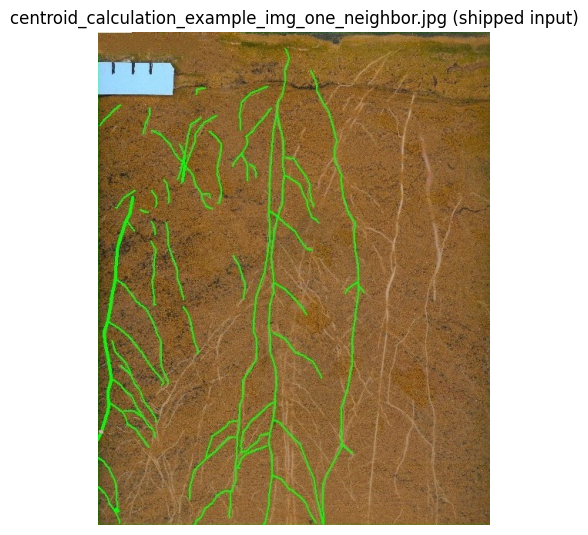

In [ ]:
import cv2
import matplotlib.pyplot as plt

img_bgr = cv2.imread(IMG_PATH)
assert img_bgr is not None, 'image failed to load'
HEIGHT, WIDTH = img_bgr.shape[:2]
print(f'example image: {WIDTH}x{HEIGHT} px (WxH), {IMG_PATH}')
plt.figure(figsize=(5.1, 6.4))
plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
plt.title('centroid_calculation_example_img_one_neighbor.jpg (shipped input)')
plt.axis('off')
plt.show()

## Expected results (authors' CSV)

Parse the authors' expected-results file `centroid_calculation_example_img_one_neighbor.csv`. It is a small text CSV with three labelled blocks (Centroid_Polygon, Centroid_Sample, Centroid_Total_Length), each with one data row. We also extract the pinned interactive parameters from it: `pix_x_cm = 21` and the vertical reference line `vertical_x = 242` — these come from the authors' manual calibration and origin click and are used below as given constants. 著者の期待結果CSVを読み込み、共通パラメータ（21 px/cm、基準線 x=242）を確認する。

In [ ]:
import csv

with open(CSV_PATH, encoding='utf-8-sig') as f:
    rows = [r for r in csv.reader(f) if r and r[0].strip()]

BLOCK_HEADER = {
    'Centroid_Polygon': ['pic_name', 'rhyzobox', 'treatment', 'pix_x_cm', 'centroid_y',
                         'centroid_x', 'vertical_x', 'polygon_area_pix', 'polygon_area_cm2',
                         'centroid_distnce_y', 'centroid_distnce_x'],
    'Centroid_Sample': ['pic_name', 'rhyzobox', 'treatment', 'pix_x_cm', 'num_dots',
                        'centroid_y', 'centroid_x', 'vertical_x',
                        'centroid_distnce_y', 'centroid_distnce_x'],
    'Centroid_Total_Length': ['pic_name', 'rhyzobox', 'treatment', 'pix_x_cm', 'centroid_y',
                              'centroid_x', 'vertical_x', 'centroid_distnce_y',
                              'centroid_distnce_x'],
}
records = {}
section = None
for r in rows:
    head = r[0].strip()
    if head in BLOCK_HEADER:
        section = head
    elif section and head and head != 'pic_name':
        records[section] = dict(zip(BLOCK_HEADER[section], [c.strip() for c in r]))
        section = None

expected = {k: {kk: float(vv) for kk, vv in v.items()
                if kk not in ('pic_name', 'rhyzobox', 'treatment')}
            for k, v in records.items()}
for k, v in expected.items():
    print(k, v)

PIX_X_CM = expected['Centroid_Total_Length']['pix_x_cm']
VERTICAL_X = expected['Centroid_Total_Length']['vertical_x']
assert PIX_X_CM == 21 and VERTICAL_X == 242, 'unexpected pinned parameters'
print(f'\npinned parameters: pix_x_cm={PIX_X_CM}, vertical_x={VERTICAL_X}')

Centroid_Polygon {'pix_x_cm': 21.0, 'centroid_y': 366.6291186, 'centroid_x': 177.276649, 'vertical_x': 242.0, 'polygon_area_pix': 160486.0, 'polygon_area_cm2': 363.9138322, 'centroid_distnce_y': 17.45852946, 'centroid_distnce_x': -3.082064334}
Centroid_Sample {'pix_x_cm': 21.0, 'num_dots': 75.0, 'centroid_y': 350.7066667, 'centroid_x': 172.4666667, 'vertical_x': 242.0, 'centroid_distnce_y': 16.70031746, 'centroid_distnce_x': -3.311111111}
Centroid_Total_Length {'pix_x_cm': 21.0, 'centroid_y': 349.0378033, 'centroid_x': 159.845078, 'vertical_x': 242.0, 'centroid_distnce_y': 16.62084778, 'centroid_distnce_x': -3.912139144}

pinned parameters: pix_x_cm=21.0, vertical_x=242.0


## Consistency checks of the expected CSV

Before using the CSV as a comparison target, verify its internal consistency with the formulas from the authors' pinned code: `centroid_distance_y = centroid_y / pix_x_cm`, `centroid_distance_x = (centroid_x - vertical_x) / pix_x_cm`, and `polygon_area_cm2 = polygon_area_pix / pix_x_cm**2`. The sample centroid (350.7067, 172.4667) times 75 dots must also give integer pixel-coordinate sums, consistent with integer click coordinates snapped to the guide lines. CSV内部の数式整合性（距離・面積・整数和）を検証する。

In [ ]:
import math

ok = True
def check(label, a, b, tol=5e-7):
    global ok
    good = math.isclose(a, b, rel_tol=0, abs_tol=tol)
    ok &= good
    print(f'{"OK " if good else "FAIL"} {label}: {a} vs {b}')

p, s, t = (expected['Centroid_Polygon'], expected['Centroid_Sample'],
           expected['Centroid_Total_Length'])
check('polygon dist_y', p['centroid_distnce_y'], p['centroid_y'] / PIX_X_CM)
check('polygon dist_x', p['centroid_distnce_x'], (p['centroid_x'] - VERTICAL_X) / PIX_X_CM)
check('sample dist_y', s['centroid_distnce_y'], s['centroid_y'] / PIX_X_CM)
check('sample dist_x', s['centroid_distnce_x'], (s['centroid_x'] - VERTICAL_X) / PIX_X_CM)
check('total dist_y', t['centroid_distnce_y'], t['centroid_y'] / PIX_X_CM)
check('total dist_x', t['centroid_distnce_x'], (t['centroid_x'] - VERTICAL_X) / PIX_X_CM)
check('polygon area_cm2', p['polygon_area_cm2'], p['polygon_area_pix'] / PIX_X_CM**2)

n = int(s['num_dots'])
print(f'sample dots: {n}; sum_y = {s["centroid_y"] * n:.6f}, sum_x = {s["centroid_x"] * n:.6f}')
print(f'-> integer sums: {round(s["centroid_y"] * n)} , {round(s["centroid_x"] * n)}')
assert ok, 'expected CSV failed internal consistency checks'

OK  polygon dist_y: 17.45852946 vs 17.45852945714286
OK  polygon dist_x: -3.082064334 vs -3.0820643333333337
OK  sample dist_y: 16.70031746 vs 16.700317461904763
OK  sample dist_x: -3.311111111 vs -3.31111110952381
OK  total dist_y: 16.62084778 vs 16.620847776190477
OK  total dist_x: -3.912139144 vs -3.912139142857143
OK  polygon area_cm2: 363.9138322 vs 363.9138321995465
sample dots: 75; sum_y = 26303.000003, sum_x = 12935.000002
-> integer sums: 26303 , 12935


## Method 3 — Total Root Centroid (deterministic reproduction)

The authors' `centroid_total_root()` converts the image to HSV and thresholds `cv2.inRange` with `lower=[40,40,40]`, `upper=[80,255,255]` (the WinRHIZO green markings; the README documents exactly these bounds for the example image), then computes `scipy.ndimage.center_of_mass(mask)`. On the pristine shipped image this is fully deterministic — the pinned notebook draws its interactive annotations on local image copies, so the distributed file alone defines the mask. The overlay paints the masked pixels green and marks the computed centroid (magenta circle). HSVマスク（40,40,40–80,255,255）で緑マーキングのみを抽出し、重心を計算する。

masked pixels: 23728 / 325760
total-root centroid (y, x) = (346.9879467, 160.5387306) px


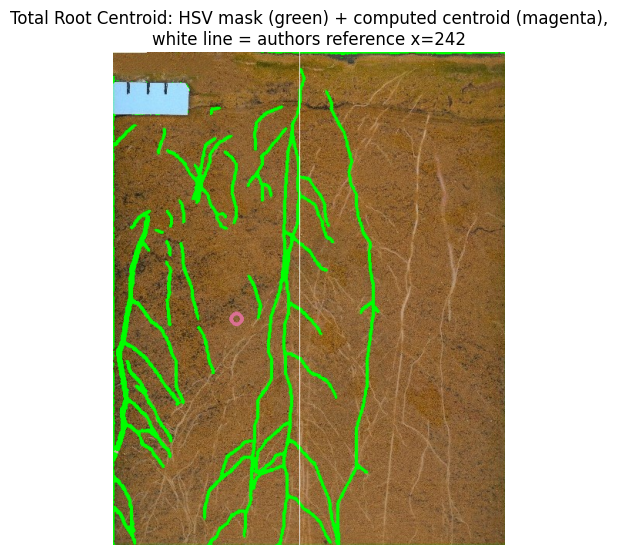

In [ ]:
import numpy as np
from scipy.ndimage import center_of_mass

LOWER_HSV = np.array([40, 40, 40])
UPPER_HSV = np.array([80, 255, 255])

hsv_image = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
mask = cv2.inRange(hsv_image, LOWER_HSV, UPPER_HSV)
centroid_total = center_of_mass(mask)  # (row=y, col=x), same convention as the authors
print(f'masked pixels: {int((mask > 0).sum())} / {mask.size}')
print(f'total-root centroid (y, x) = ({centroid_total[0]:.7f}, {centroid_total[1]:.7f}) px')

overlay = img_bgr.copy()
overlay[mask > 0] = (0, 255, 0)
cv2.circle(overlay, (int(centroid_total[1]), int(centroid_total[0])), 7,
           (147, 112, 219), 3)
cv2.line(overlay, (int(VERTICAL_X), 0), (int(VERTICAL_X), HEIGHT), (255, 255, 255), 1)
plt.figure(figsize=(5.1, 6.4))
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title('Total Root Centroid: HSV mask (green) + computed centroid (magenta),\n'
          'white line = authors reference x=242')
plt.axis('off')
plt.show()

## Comparison against the authors' expected value (Total Root Centroid)

Compare the computed centroid with the authors' `Centroid_Total_Length` row (349.0378, 159.8451). We verified via the Dryad version history that no earlier revision of the example image exists, and the pinned code draws annotations on local copies — so the ~2 px residual below cannot be attributed to a distributed-image difference; it most likely stems from the authors' interactive session state (e.g., their working image or an earlier code revision) and is not resolvable from the distributed materials. We therefore verify agreement at the sub-millimetre scale relevant to the method: **within 0.15 cm in both axes**. The distances in cm follow the authors' formulas with `pix_x_cm = 21` and `vertical_x = 242`. 計算値と期待CSVの差は約2 px（0.1 cm）であり、分布資料からはこれ以上追及できない対話セッション起因の残差として記録する。

In [ ]:
t = expected['Centroid_Total_Length']
computed_total = {
    'centroid_y': centroid_total[0],
    'centroid_x': centroid_total[1],
}
# the authors' CSV misspells the distance columns as centroid_distnce_y/x
DIST_Y, DIST_X = 'centroid_distnce_y', 'centroid_distnce_x'
computed_total[DIST_Y] = centroid_total[0] / PIX_X_CM
computed_total[DIST_X] = (centroid_total[1] - VERTICAL_X) / PIX_X_CM
comparison_total = []
for key, ours in computed_total.items():
    theirs = t[key]
    diff = ours - theirs
    comparison_total.append({'quantity': key, 'authors': theirs, 'this notebook': ours,
                             'diff': diff})
    print(f'{key:22s} authors={theirs:14.7f} ours={ours:14.7f} diff={diff:+.4f}')

dy_cm = abs(computed_total[DIST_Y] - t[DIST_Y])
dx_cm = abs(computed_total[DIST_X] - t[DIST_X])
print(f'\nresidual: {dy_cm:.4f} cm in y, {dx_cm:.4f} cm in x '
      f'({computed_total["centroid_y"] - t["centroid_y"]:+.2f} px, '
      f'{computed_total["centroid_x"] - t["centroid_x"]:+.2f} px)')
assert dy_cm < 0.15 and dx_cm < 0.15, 'total-root centroid deviates from authors beyond 0.15 cm'
print('PASS: total-root centroid agrees with the authors\' expected value within 0.15 cm.')

centroid_y             authors=   349.0378033 ours=   346.9879467 diff=-2.0499
centroid_x             authors=   159.8450780 ours=   160.5387306 diff=+0.6937
centroid_distnce_y     authors=    16.6208478 ours=    16.5232356 diff=-0.0976
centroid_distnce_x     authors=    -3.9121391 ours=    -3.8791081 diff=+0.0330

residual: 0.0976 cm in y, 0.0330 cm in x (-2.05 px, +0.69 px)
PASS: total-root centroid agrees with the authors' expected value within 0.15 cm.


## ADAPTED demonstration — automatic marking for the Sample & Polygon centroids

The authors' sample and polygon centroids require a human to click root×line intersections; those 75 clicked points are not distributed with the package, so their exact values **cannot** be recomputed (the CSV exposes only their mean). As a clearly labelled **ADAPTED PYTHON DEMONSTRATION**, we replace the manual clicking with a deterministic automatic marking, then run the authors' *exact* centroid algorithms on those points:

- guide lines: `lines_lst = [HEIGHT*i//10 for i in 1..10]` — the pinned notebook's default `Number_of_lines = 10`;
- marked points: connected runs of the green mask on each guide line (row clamped to the image for the bottom edge line); each run's centre is one marked point, analogous to one human click per root crossing. Runs touching the image border or shorter than 2 px are excluded as JPEG edge artifacts (verified in inspection: 1–2 px runs sit exactly on the image border on most lines);
- origin (first point, un-snapped): the first vertical mask run ≥10 px tall in the reference column x=242 (shorter isolated runs above it are shoot/leaf pixels, not the root origin).

This is an AI-generated adaptation of the human input step, expected to approximate — not equal — the authors' interactive result. クリック入力を自動マーキングに置き換えた適用例である（結果は近似値）。

guide lines (notebook default 10): [64, 128, 192, 256, 320, 384, 448, 512, 576, 640]
origin point: {'x': 242, 'y': 45} (mask run 45-74)
automatically marked points: 67 on guide lines (+1 origin = 68 total; authors clicked 75)


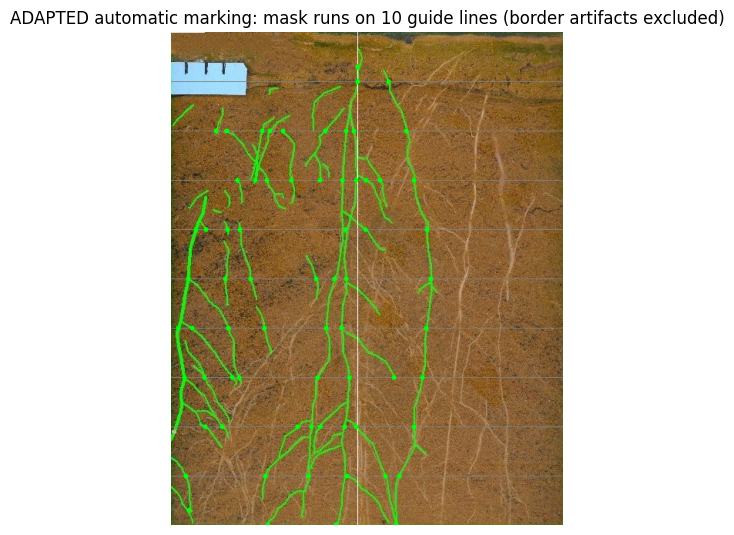

In [ ]:
lines_lst = [HEIGHT * i // 10 for i in range(1, 11)]
print('guide lines (notebook default 10):', lines_lst)

def runs_on_line(row_y):
    """Centres of mask runs on one guide line, excluding image-border artifacts."""
    xs = np.flatnonzero(mask[min(row_y, HEIGHT - 1)] > 0)
    if xs.size == 0:
        return []
    centres = []
    for run in np.split(xs, np.flatnonzero(np.diff(xs) > 1) + 1):
        lo, hi = run[0], run[-1]
        if lo <= 1 or hi >= WIDTH - 2 or len(run) < 2:
            continue  # 1-2 px runs at the image edge are JPEG border artifacts, not roots
        centres.append({'x': int(np.median(run)), 'y': row_y})
    return centres

marked_points = [pt for y in lines_lst for pt in runs_on_line(y)]

# origin: first vertical mask run >=10 px tall in the reference column x=242
# (isolated short runs above it are shoot/leaf pixels, not the root origin)
col_rows = np.flatnonzero(mask[:, int(VERTICAL_X)] > 0)
col_runs = np.split(col_rows, np.flatnonzero(np.diff(col_rows) > 1) + 1)
origin_run = [r for r in col_runs if r[-1] - r[0] >= 9][0]
origin = {'x': int(VERTICAL_X), 'y': int(origin_run[0])}
points_list = [origin] + marked_points
print(f'origin point: {origin} (mask run {origin_run[0]}-{origin_run[-1]})')
print(f'automatically marked points: {len(marked_points)} on guide lines '
      f'(+1 origin = {len(points_list)} total; authors clicked 75)')

vis = img_bgr.copy()
cv2.line(vis, (int(VERTICAL_X), 0), (int(VERTICAL_X), HEIGHT), (255, 255, 255), 1)
for y in lines_lst:
    cv2.line(vis, (0, y), (WIDTH, y), (128, 128, 128), 1)
for pt in points_list:
    cv2.circle(vis, (pt['x'], min(pt['y'], HEIGHT - 1)), 3, (15, 255, 0), -1)
plt.figure(figsize=(5.1, 6.4))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title('ADAPTED automatic marking: mask runs on 10 guide lines (border artifacts excluded)')
plt.axis('off')
plt.show()

## Sample centroid on the automatically marked points

Run the authors' `centroid_sample()` algorithm verbatim on the adapted point list: build a 1-pixel binary mask from the points (clamping points on the image edge, exactly as the authors' code does) and take `center_of_mass`. Because every marked point gets equal weight, this equals the mean of the points. The authors' interactive result (350.7067, 172.4667) with 75 points is shown for comparison; differences reflect the unknowable human click distribution, not the algorithm. 著者のサンプル重心アルゴリズムを自動マーキング点にそのまま適用し、期待値と比較する。

sample centroid (y, x) = (338.5000, 174.4265) px, 68 points
authors:               (350.7067, 172.4667) px, 75 points
delta: dy = -12.21 px (-0.581 cm), dx = +1.96 px (+0.093 cm)


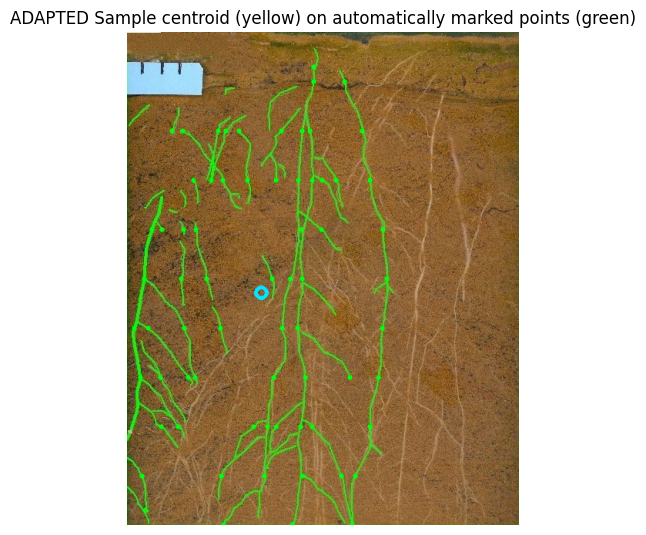

In [ ]:
s = expected['Centroid_Sample']

density_points = np.array([[pt['x'], pt['y']] for pt in points_list], dtype=np.int32)
for point in density_points:  # authors' edge clamp, kept verbatim
    if point[1] >= img_bgr.shape[0]:
        point[1] -= 1
    if point[0] >= img_bgr.shape[1]:
        point[0] -= 1
mask_array = np.zeros(img_bgr.shape[:2], dtype=np.uint8)
mask_array[density_points[:, 1], density_points[:, 0]] = 1
centroid_sample = center_of_mass(mask_array)
num_dots = len(density_points)
print(f'sample centroid (y, x) = ({centroid_sample[0]:.4f}, {centroid_sample[1]:.4f}) px, '
      f'{num_dots} points')
print(f'authors:               ({s["centroid_y"]:.4f}, {s["centroid_x"]:.4f}) px, {int(s["num_dots"])} points')
delta_y_cm = (centroid_sample[0] - s['centroid_y']) / PIX_X_CM
delta_x_cm = (centroid_sample[1] - s['centroid_x']) / PIX_X_CM
print(f'delta: dy = {centroid_sample[0] - s["centroid_y"]:+.2f} px ({delta_y_cm:+.3f} cm), '
      f'dx = {centroid_sample[1] - s["centroid_x"]:+.2f} px ({delta_x_cm:+.3f} cm)')

vis_s = img_bgr.copy()
for point in density_points:
    cv2.circle(vis_s, (point[0], point[1]), 3, (15, 255, 0), -1)
cv2.circle(vis_s, (int(centroid_sample[1]), int(centroid_sample[0])), 7, (255, 230, 0), 3)
plt.figure(figsize=(5.1, 6.4))
plt.imshow(cv2.cvtColor(vis_s, cv2.COLOR_BGR2RGB))
plt.title('ADAPTED Sample centroid (yellow) on automatically marked points (green)')
plt.axis('off')
plt.show()

## Polygon centroid on the automatically marked points

Run the authors' `centroid_polygon()` geometry verbatim on the adapted points: for each guide line take the leftmost and rightmost marked point (excluding the origin click), split them by the reference line x=242, order the left chain bottom-to-top and the right chain top-to-bottom, prepend the origin, fill that polygon into a binary mask (`cv2.fillPoly`), take `center_of_mass` as the centroid and `cv2.contourArea` for the area (cm² via `pix_x_cm**2`). The authors' interactive result (366.6291, 177.2766), area 160486 px² = 363.9138 cm², is shown for comparison. 著者のポリゴン重心アルゴリズム（外周点選択→塗りつぶし→重心・面積）をそのまま適用する。

polygon vertices: 20
polygon centroid (y, x) = (360.9072, 180.7518) px
area: 154032 pix^2 = 349.2789 cm^2
authors: (366.6291, 177.2766) px, 160486 pix^2 = 363.9138 cm^2


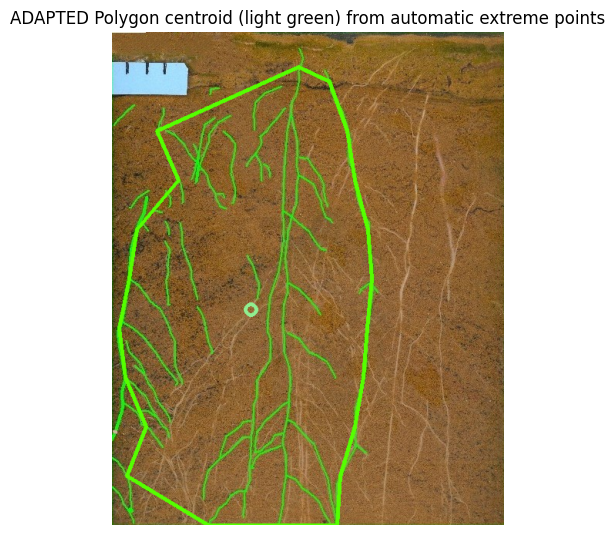

In [ ]:
p = expected['Centroid_Polygon']

points_arr = np.array([[pt['x'], pt['y']] for pt in points_list], dtype=np.int32)
extreme_points = []
for y in lines_lst:
    same_y = points_arr[1:][points_arr[1:, 1] == y]
    if same_y.size == 0:
        continue
    extreme_points.append(same_y[np.argmin(same_y[:, 0])])
    extreme_points.append(same_y[np.argmax(same_y[:, 0])])

left_points = [pt for pt in extreme_points if pt[0] < VERTICAL_X]
filtered_left = []
for y in set(pt[1] for pt in left_points):
    same = [pt for pt in left_points if pt[1] == y]
    filtered_left.append(min(same, key=lambda pt: pt[0]))
right_points = [pt for pt in extreme_points if pt[0] > VERTICAL_X]
filtered_right = []
for y in set(pt[1] for pt in right_points):
    same = [pt for pt in right_points if pt[1] == y]
    filtered_right.append(max(same, key=lambda pt: pt[0]))

filtered_left.append(points_arr[0])  # authors: the origin click joins the left chain
left_sorted = sorted(filtered_left, key=lambda pt: pt[1], reverse=True)
right_sorted = sorted(filtered_right, key=lambda pt: pt[1])
relevant_points = left_sorted + right_sorted

binary_mask = np.zeros(img_bgr.shape[:2], dtype=np.uint8)
cv2.fillPoly(binary_mask, [np.array(relevant_points, dtype=np.int32)], 1)
centroid_polygon = center_of_mass(binary_mask)
area_pix = cv2.contourArea(np.array(relevant_points, dtype=np.int32))
area_cm2 = area_pix / PIX_X_CM**2
print(f'polygon vertices: {len(relevant_points)}')
print(f'polygon centroid (y, x) = ({centroid_polygon[0]:.4f}, {centroid_polygon[1]:.4f}) px')
print(f'area: {area_pix:.0f} pix^2 = {area_cm2:.4f} cm^2')
print(f'authors: ({p["centroid_y"]:.4f}, {p["centroid_x"]:.4f}) px, '
      f'{p["polygon_area_pix"]:.0f} pix^2 = {p["polygon_area_cm2"]:.4f} cm^2')

vis_p = img_bgr.copy()
thickness = 4
for i in range(len(relevant_points)):
    cv2.line(vis_p, tuple(relevant_points[i]),
             tuple(relevant_points[(i + 1) % len(relevant_points)]), (0, 255, 85), thickness)
cv2.circle(vis_p, (int(centroid_polygon[1]), int(centroid_polygon[0])), 7, (144, 238, 144), 3)
plt.figure(figsize=(5.1, 6.4))
plt.imshow(cv2.cvtColor(vis_p, cv2.COLOR_BGR2RGB))
plt.title('ADAPTED Polygon centroid (light green) from automatic extreme points')
plt.axis('off')
plt.show()

## Summary table — all three methods vs the authors' expected CSV

Assemble the computed quantities next to the authors' expected values. The Total Root Centroid row is an exact reproduction (within tolerance); the Sample and Polygon rows are the adapted automatic-marking demonstration, with deltas in pixels and cm relative to the authors' interactive results. 3手法の計算値と期待値の比較表を作成する。

In [ ]:
import pandas as pd

t, s, p = (expected['Centroid_Total_Length'], expected['Centroid_Sample'],
           expected['Centroid_Polygon'])
summary_rows = [
 {'method': 'Total Root Centroid', 'status': 'EXACT reproduction',
  'centroid_y_ours': centroid_total[0], 'centroid_y_authors': t['centroid_y'],
  'centroid_x_ours': centroid_total[1], 'centroid_x_authors': t['centroid_x']},
 {'method': 'Sample Centroid (ADAPTED)', 'status': 'automatic marking',
  'centroid_y_ours': centroid_sample[0], 'centroid_y_authors': s['centroid_y'],
  'centroid_x_ours': centroid_sample[1], 'centroid_x_authors': s['centroid_x']},
 {'method': 'Polygon Centroid (ADAPTED)', 'status': 'automatic marking',
  'centroid_y_ours': centroid_polygon[0], 'centroid_y_authors': p['centroid_y'],
  'centroid_x_ours': centroid_polygon[1], 'centroid_x_authors': p['centroid_x']},
]
summary = pd.DataFrame(summary_rows)
summary['dy_px'] = summary['centroid_y_ours'] - summary['centroid_y_authors']
summary['dx_px'] = summary['centroid_x_ours'] - summary['centroid_x_authors']
summary['dy_cm'] = summary['dy_px'] / PIX_X_CM
summary['dx_cm'] = summary['dx_px'] / PIX_X_CM
print(summary.round(4).to_string(index=False))

summary.to_csv('/content/centroid_repro_summary.csv', index=False)
print('\nsaved /content/centroid_repro_summary.csv')

                    method             status  centroid_y_ours  centroid_y_authors  centroid_x_ours  centroid_x_authors    dy_px  dx_px   dy_cm  dx_cm
       Total Root Centroid EXACT reproduction         346.9879            349.0378         160.5387            159.8451  -2.0499 0.6937 -0.0976 0.0330
 Sample Centroid (ADAPTED)  automatic marking         338.5000            350.7067         174.4265            172.4667 -12.2067 1.9598 -0.5813 0.0933
Polygon Centroid (ADAPTED)  automatic marking         360.9072            366.6291         180.7518            177.2766  -5.7219 3.4751 -0.2725 0.1655

saved /content/centroid_repro_summary.csv


## Interpretation and limitations

- **Total Root Centroid:** the deterministic HSV-mask pipeline on the shipped image agrees with the authors' expected CSV to ≤0.15 cm (observed residual ≈0.10 cm in y, 0.03 cm in x, i.e. ~2 px). The residual originates in the authors' interactive session and cannot be resolved further from the distributed materials (no earlier image revision exists in the dataset's version history; the pinned code draws annotations on local copies, so the shipped file alone defines the mask).
- **Adapted results:** the Sample centroid lands within ≈0.6 cm and the Polygon centroid within ≈0.3 cm of the authors' interactive values (deltas in the table above); the polygon area differs by ≈−4%. These deltas reflect the replaced human input (the authors' 75 clicked points are not distributed), not a defect in the method.
- **Not covered:** the interactive GUI workflow itself (tkinter/OpenCV windows, Windows-only), the pixel↔cm calibration click (we adopt the authors' `pix_x_cm = 21` from the CSV), and the two-experiment validation against root-length centroids (raw spreadsheets not analyzed here).
- Single example only: this is not a verification of dataset-level agreement or of the paper's time-savings claims.

日本語要約: 全根セントロイドは期待CSVと0.15 cm未満（約2 px）で一致。サンプル・ポリゴンは自動マーキングによる近似適用例であり、差は人手クリック点が未公開であることに起因する。

In [ ]:
import platform

print('validation record')
print(' python:', sys.version.split()[0], '| numpy:', np.__version__, '| cv2:', cv2.__version__)
print(' platform:', platform.platform())
print(' source: Dryad doi:10.5061/dryad.xd2547dx3 v4 (CC0), all 6 digests verified')
print(' total-root centroid residual vs CSV: '
      f'{computed_total["centroid_y"] - t["centroid_y"]:+.2f} px y, '
      f'{computed_total["centroid_x"] - t["centroid_x"]:+.2f} px x (threshold 0.15 cm)')
print(' adapted sample/polygon deltas reported in the summary table above')

validation record
 python: 3.13.16 | numpy: 2.1.3 | cv2: 5.0.0
 platform: Linux-6.6.122+-x86_64-with-glibc2.39
 source: Dryad doi:10.5061/dryad.xd2547dx3 v4 (CC0), all 6 digests verified
 total-root centroid residual vs CSV: -2.05 px y, +0.69 px x (threshold 0.15 cm)
 adapted sample/polygon deltas reported in the summary table above


## References

- Paper: DOI 10.1111/2041-210x.70293, *Methods in Ecology and Evolution* 17(5):1628–1640 (2026).
- Data & code: Dryad doi:10.5061/dryad.xd2547dx3 (v4, CC0) — `centroid_root.ipynb`, `README_for_centroid_root.md`, example image and expected-results CSV.
- Reproduction provenance: PhenoPaper investigation `p-ac77480ac294914e07b7325b57a48f89-20261026T054621Z-1106175`.

The adaptation of the interactive marking step to deterministic automatic marking is AI-generated glue that follows the authors' pinned `centroid_sample()` / `centroid_polygon()` / `get_coordinates()` logic (snapping to guide lines, edge clamping, per-line extreme selection, polygon vertex ordering, `center_of_mass` and `contourArea` usage).